#### Imports Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Optional
try:
    from xgboost import XGBRegressor
    xgb_available = True
except ImportError:
    print("XGBoost not installed. Continuing without it.")
    xgb_available = False

#### Load Raw Datasets

In [2]:
climate = pd.read_csv("data/raw/climate_data.csv")
wapor = pd.read_csv("data/raw/wapor_data.csv")
soil_moisture = pd.read_csv("data/raw/soil_moisture.csv")
soil_properties = pd.read_csv("data/raw/soil_properties.csv")
vegetation = pd.read_csv("data/raw/vegetation_data.csv")
targets = pd.read_csv("data/raw/resource_targets.csv")

#### Initial Inspection

In [3]:
datasets = {
    "climate": climate,
    "wapor": wapor,
    "soil_moisture": soil_moisture,
    "soil_properties": soil_properties,
    "vegetation": vegetation,
    "targets": targets
}

for name, df in datasets.items():
    print(f"\n{'='*40}")
    print(f"{name.upper()}")
    print(df.head())
    print(df.info())
    print(df.isnull().sum())
    print("Duplicates:", df.duplicated().sum())


CLIMATE
         date   latitude  longitude  temperature   humidity  rainfall  \
0  2022-01-01  30.249080  72.681757    29.667921  54.251693  3.134239   
1  2022-01-02  31.401429  72.991703    34.319957  67.483971  1.495231   
2  2022-01-03  30.963988  71.626170    34.196383  83.354288  6.740961   
3  2022-01-04  30.697317  72.562185    24.769519  42.589595  5.627177   
4  2022-01-05  29.812037  72.429365    30.627408  88.912638  0.829729   

   solar_radiation  wind_speed  
0        21.067964    3.028908  
1        12.655934    1.741783  
2        16.854681    3.021695  
3        20.203845    4.894131  
4        28.074651    4.402095  
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   date             3000 non-null   str    
 1   latitude         3000 non-null   float64
 2   longitude        3000 non-null   float64
 3   temperature      3000 no

#### Convert Date Columns

In [4]:
for df in [climate, wapor, soil_moisture, vegetation, targets]:
    df["date"] = pd.to_datetime(df["date"])

#### Merge Datasets

In [5]:
merged = climate.merge(wapor, on=["date", "latitude", "longitude"], how="inner")
merged = merged.merge(soil_moisture, on=["date", "latitude", "longitude"], how="inner")
merged = merged.merge(vegetation, on=["date", "latitude", "longitude"], how="inner")

print("Shape after merging dynamic datasets:", merged.shape)
print(merged.head())

Shape after merging dynamic datasets: (3000, 14)
        date   latitude  longitude  temperature   humidity  rainfall  \
0 2022-01-01  30.249080  72.681757    29.667921  54.251693  3.134239   
1 2022-01-02  31.401429  72.991703    34.319957  67.483971  1.495231   
2 2022-01-03  30.963988  71.626170    34.196383  83.354288  6.740961   
3 2022-01-04  30.697317  72.562185    24.769519  42.589595  5.627177   
4 2022-01-05  29.812037  72.429365    30.627408  88.912638  0.829729   

   solar_radiation  wind_speed  evapotranspiration      biomass  \
0        21.067964    3.028908            5.384675  1589.675093   
1        12.655934    1.741783            4.240317  2225.179165   
2        16.854681    3.021695            6.650225  2858.802728   
3        20.203845    4.894131            7.306788  1261.613139   
4        28.074651    4.402095            2.358307  2995.928934   

   water_productivity  soil_moisture      ndvi  land_surface_temp  
0            1.251538       0.258464  0.691488 

#### Attach field_id From Targets

In [6]:
merged["field_id"] = targets["field_id"].values

#### Merge Targets and Soil Properties

In [7]:
merged = merged.merge(targets, on=["date", "field_id"], how="inner")
merged = merged.merge(soil_properties, on="field_id", how="left")

print("Final merged shape:", merged.shape)
print(merged.head())
print(merged.isnull().sum())
print("Duplicates:", merged.duplicated().sum())

Final merged shape: (3000, 23)
        date   latitude  longitude  temperature   humidity  rainfall  \
0 2022-01-01  30.249080  72.681757    29.667921  54.251693  3.134239   
1 2022-01-02  31.401429  72.991703    34.319957  67.483971  1.495231   
2 2022-01-03  30.963988  71.626170    34.196383  83.354288  6.740961   
3 2022-01-04  30.697317  72.562185    24.769519  42.589595  5.627177   
4 2022-01-05  29.812037  72.429365    30.627408  88.912638  0.829729   

   solar_radiation  wind_speed  evapotranspiration      biomass  ...  \
0        21.067964    3.028908            5.384675  1589.675093  ...   
1        12.655934    1.741783            4.240317  2225.179165  ...   
2        16.854681    3.021695            6.650225  2858.802728  ...   
3        20.203845    4.894131            7.306788  1261.613139  ...   
4        28.074651    4.402095            2.358307  2995.928934  ...   

   land_surface_temp  field_id  water_used  fertilizer_used  energy_used  \
0          27.788536       

#### Save Output

In [8]:
merged.to_csv("data/processed/master_dataset.csv", index=False)
print("Saved: data/processed/master_dataset.csv")

Saved: data/processed/master_dataset.csv


#### Reload Master Dataset

In [9]:
merged = pd.read_csv("data/processed/master_dataset.csv")
merged["date"] = pd.to_datetime(merged["date"])

print(merged.shape)
print(merged.head())

(3000, 23)
        date   latitude  longitude  temperature   humidity  rainfall  \
0 2022-01-01  30.249080  72.681757    29.667921  54.251693  3.134239   
1 2022-01-02  31.401429  72.991703    34.319957  67.483971  1.495231   
2 2022-01-03  30.963988  71.626170    34.196383  83.354288  6.740961   
3 2022-01-04  30.697317  72.562185    24.769519  42.589595  5.627177   
4 2022-01-05  29.812037  72.429365    30.627408  88.912638  0.829729   

   solar_radiation  wind_speed  evapotranspiration      biomass  ...  \
0        21.067964    3.028908            5.384675  1589.675093  ...   
1        12.655934    1.741783            4.240317  2225.179165  ...   
2        16.854681    3.021695            6.650225  2858.802728  ...   
3        20.203845    4.894131            7.306788  1261.613139  ...   
4        28.074651    4.402095            2.358307  2995.928934  ...   

   land_surface_temp  field_id  water_used  fertilizer_used  energy_used  \
0          27.788536         1  275.690421     

#### Target Columns With Realistic Relationships

In [10]:
temp_norm = (merged["temperature"] - merged["temperature"].min()) / (
    merged["temperature"].max() - merged["temperature"].min()
)

soil_m_norm = (merged["soil_moisture"] - merged["soil_moisture"].min()) / (
    merged["soil_moisture"].max() - merged["soil_moisture"].min()
)

ndvi_norm = (merged["ndvi"] - merged["ndvi"].min()) / (
    merged["ndvi"].max() - merged["ndvi"].min()
)

merged["water_used"] = (
    200
    + 150 * temp_norm
    + 100 * merged["evapotranspiration"] / 8
    + np.random.normal(0, 20, len(merged))
)

merged["fertilizer_used"] = (
    50
    + 80 * (1 - soil_m_norm)
    + 50 * (1 - ndvi_norm)
    + np.random.normal(0, 10, len(merged))
)

merged["energy_used"] = (
    0.08 * merged["water_used"]
    + np.random.normal(0, 5, len(merged))
)

merged["yield_score"] = (
    0.4 * ndvi_norm
    + 0.3 * soil_m_norm
    + 0.2 * (1 - temp_norm)
    + 0.1 * (merged["organic_carbon"] / merged["organic_carbon"].max())
    + np.random.normal(0, 0.05, len(merged))
)

merged["yield_score"] = merged["yield_score"].clip(0.3, 1.0)

#### Save 2 Output

In [11]:
merged.to_csv("data/processed/master_dataset_phase2.csv", index=False)
print("Saved: data/processed/master_dataset_phase2.csv")

Saved: data/processed/master_dataset_phase2.csv


## EDA

In [12]:
print(merged.describe(include="all"))

                      date     latitude    longitude  temperature  \
count                 3000  3000.000000  3000.000000  3000.000000   
mean   2026-02-08 12:00:00    30.499786    72.235787    27.934075   
min    2022-01-01 00:00:00    29.500023    71.000077     5.820269   
25%    2024-01-20 18:00:00    29.991611    71.614319    23.931481   
50%    2026-02-08 12:00:00    30.510707    72.220097    28.037790   
75%    2028-02-28 06:00:00    31.008669    72.846476    31.947489   
max    2030-03-19 00:00:00    31.499435    73.498894    48.485122   
std                    NaN     0.583313     0.718559     5.966189   

          humidity     rainfall  solar_radiation   wind_speed  \
count  3000.000000  3000.000000      3000.000000  3000.000000   
mean     60.115226     2.920073        19.953631     4.264185   
min      30.007119     0.000527        10.000186     0.501510   
25%      45.318184     0.832345        14.954197     2.384319   
50%      60.208792     2.024475        19.958534     

#### Correlation Heatmap

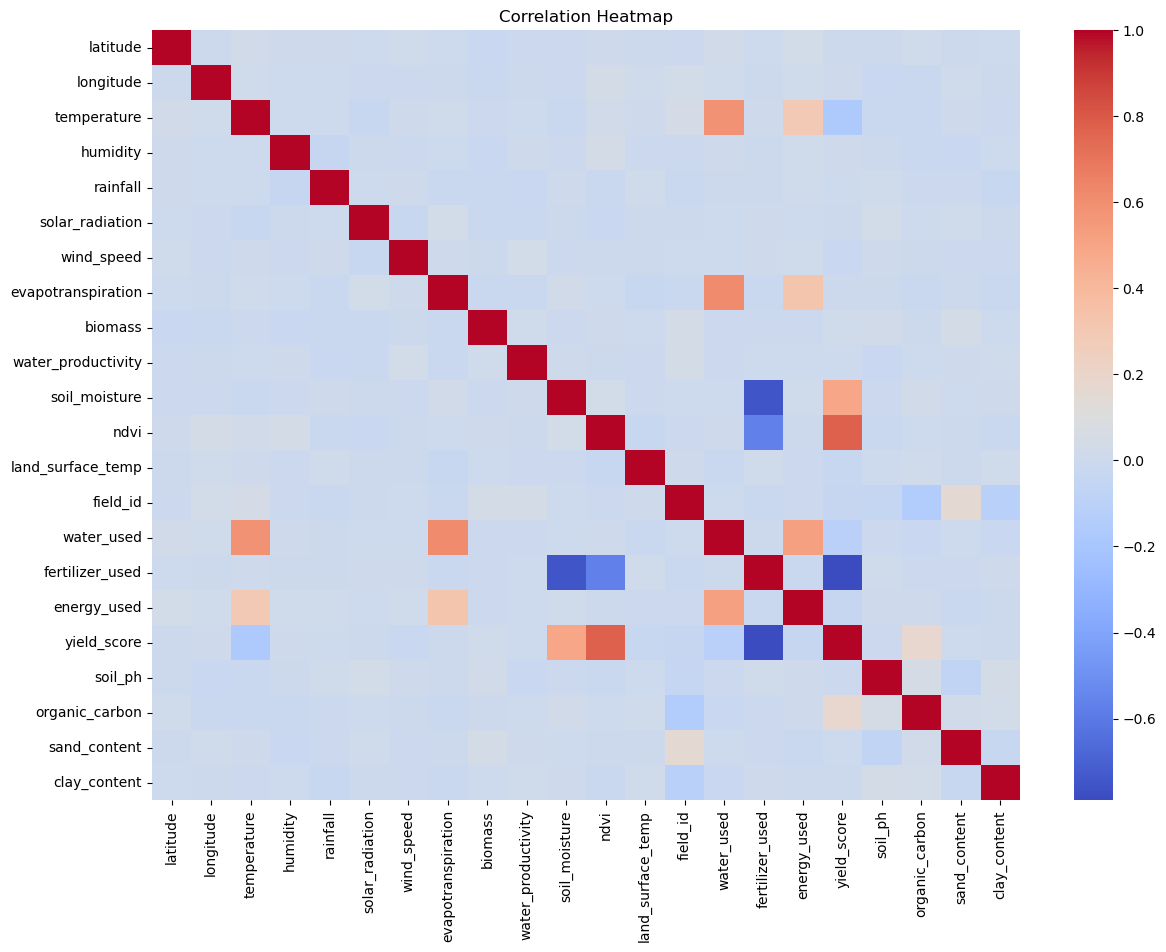

In [13]:
plt.figure(figsize=(14, 10))
sns.heatmap(merged.corr(numeric_only=True), cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

#### Histograms

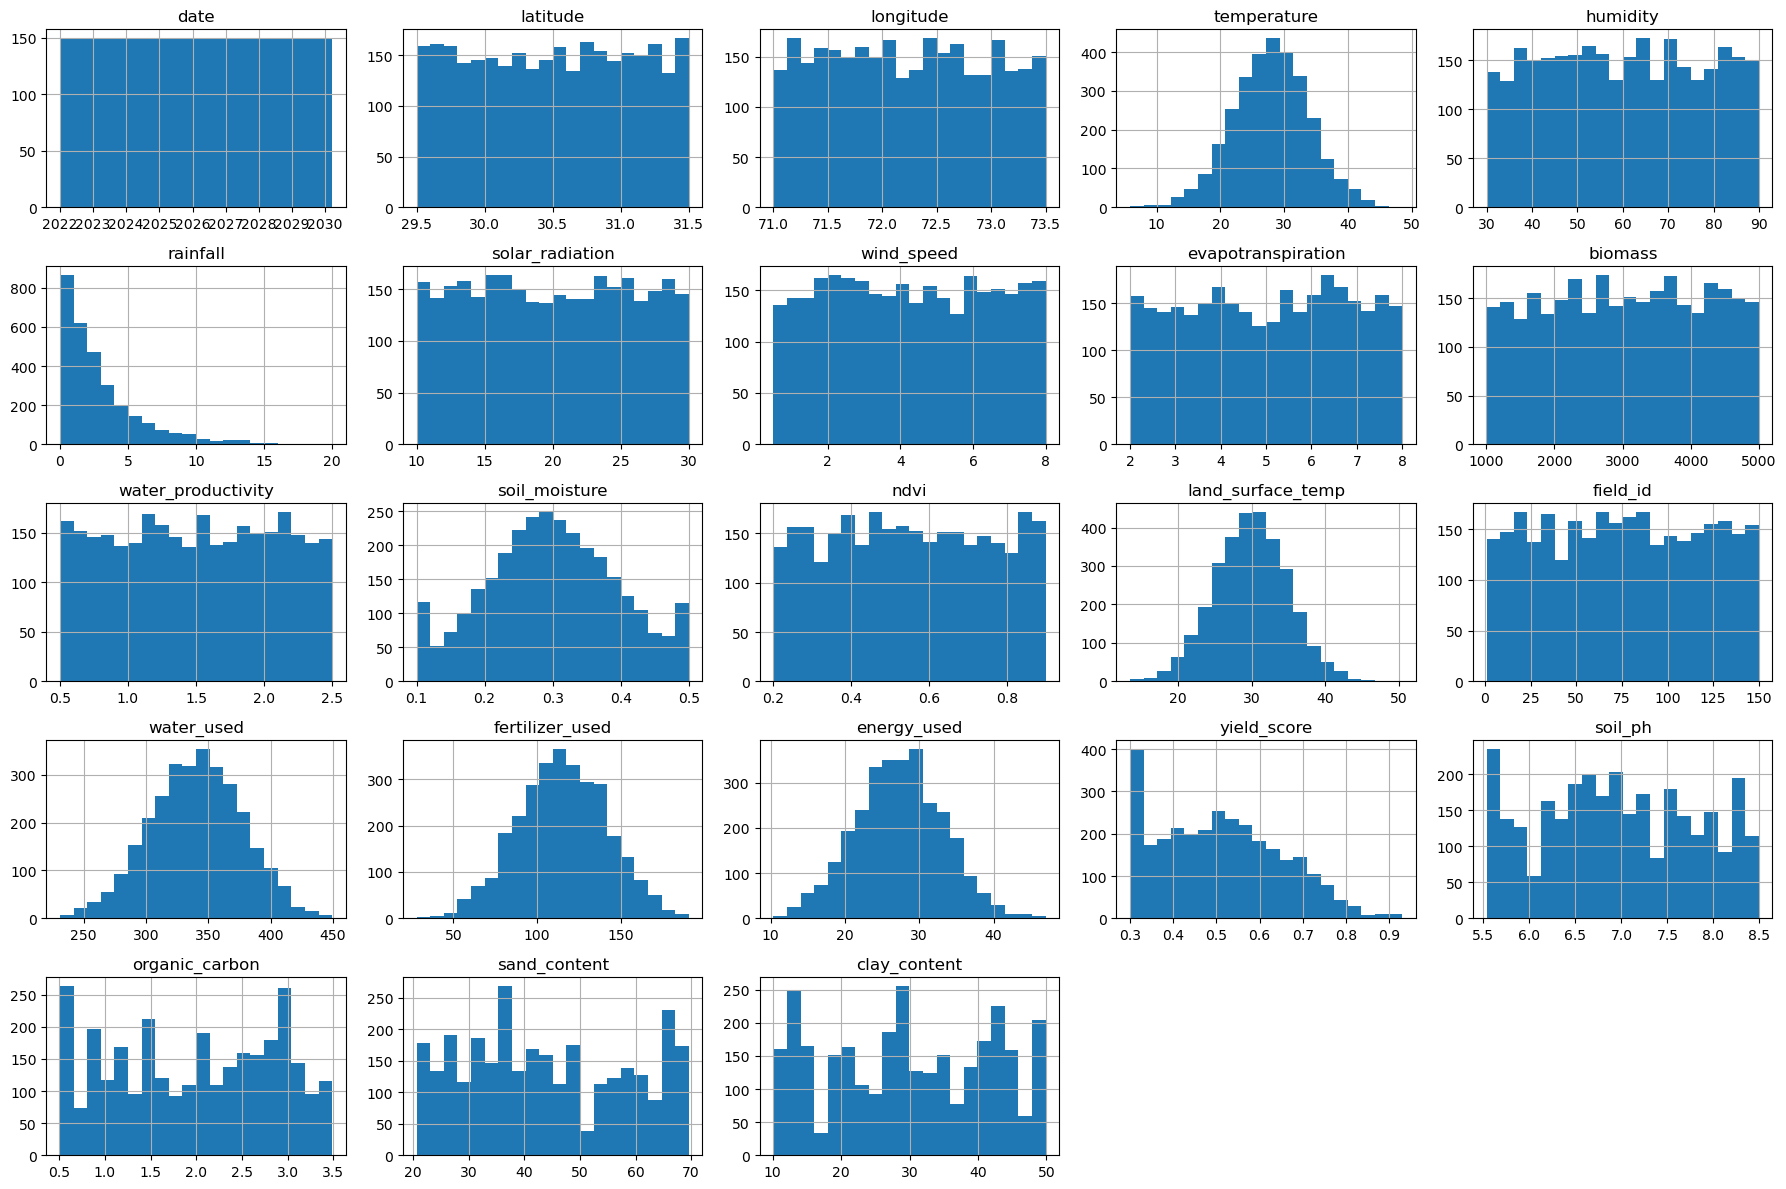

In [14]:
merged.hist(figsize=(18, 12), bins=20)
plt.tight_layout()
plt.show()

#### Scatter Plots

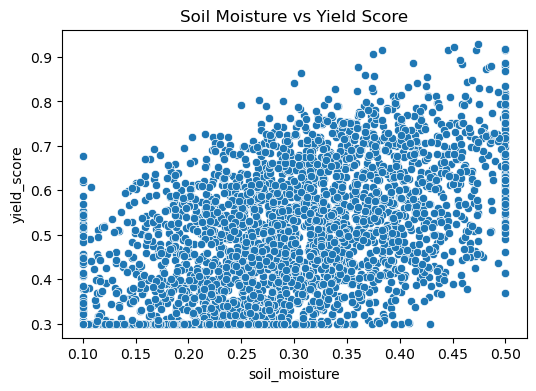

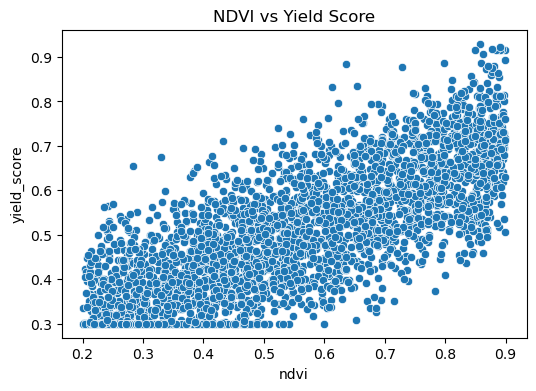

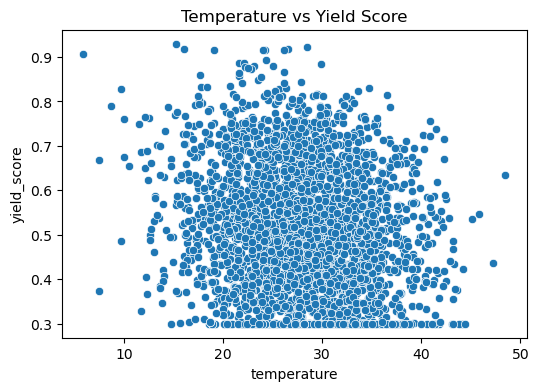

In [15]:
plt.figure(figsize=(6, 4))
sns.scatterplot(data=merged, x="soil_moisture", y="yield_score")
plt.title("Soil Moisture vs Yield Score")
plt.show()

plt.figure(figsize=(6, 4))
sns.scatterplot(data=merged, x="ndvi", y="yield_score")
plt.title("NDVI vs Yield Score")
plt.show()

plt.figure(figsize=(6, 4))
sns.scatterplot(data=merged, x="temperature", y="yield_score")
plt.title("Temperature vs Yield Score")
plt.show()

#### check Skewness

In [16]:
merged.corr(numeric_only=True)["yield_score"].sort_values()

fertilizer_used      -0.789075
temperature          -0.167634
water_used           -0.105602
energy_used          -0.036632
field_id             -0.035960
land_surface_temp    -0.032419
wind_speed           -0.021317
soil_ph              -0.008654
latitude             -0.003936
clay_content         -0.001245
solar_radiation      -0.001089
evapotranspiration   -0.000401
rainfall              0.002938
sand_content          0.003162
water_productivity    0.003462
humidity              0.008520
longitude             0.011448
biomass               0.015118
organic_carbon        0.178139
soil_moisture         0.496747
ndvi                  0.769472
yield_score           1.000000
Name: yield_score, dtype: float64

#### Reload Phase 2 Dataset

In [17]:
merged = pd.read_csv("data/processed/master_dataset_phase2.csv")
merged["date"] = pd.to_datetime(merged["date"])

#### Feature Engineering

In [18]:
merged["temp_stress"] = merged["temperature"] * merged["humidity"]
merged["water_demand"] = merged["evapotranspiration"] * merged["temperature"]
merged["soil_quality"] = (merged["organic_carbon"] + merged["soil_ph"]) / 2

print(merged[["temp_stress", "water_demand", "soil_quality"]].head())

   temp_stress  water_demand  soil_quality
0  1609.534929    159.752115      4.820720
1  2316.047016    145.527486      4.341254
2  2850.415139    227.413624      4.981554
3  1054.923771    180.985620      3.872063
4  2723.163670     72.228841      5.521329


#### Save Phase 3 Output

In [19]:
merged.to_csv("data/processed/master_dataset_phase3.csv", index=False)
print("Saved: data/processed/master_dataset_phase3.csv")

Saved: data/processed/master_dataset_phase3.csv


#### Build Yield Prediction Dataset

In [20]:
merged = pd.read_csv("data/processed/master_dataset_phase3.csv")
merged["date"] = pd.to_datetime(merged["date"])

X = merged.drop(columns=[
    "yield_score",
    "water_used",
    "fertilizer_used",
    "energy_used",
    "date"
])

y = merged["yield_score"]

print(X.columns)
print(X.shape, y.shape)

Index(['latitude', 'longitude', 'temperature', 'humidity', 'rainfall',
       'solar_radiation', 'wind_speed', 'evapotranspiration', 'biomass',
       'water_productivity', 'soil_moisture', 'ndvi', 'land_surface_temp',
       'field_id', 'soil_ph', 'organic_carbon', 'sand_content', 'clay_content',
       'temp_stress', 'water_demand', 'soil_quality'],
      dtype='str')
(3000, 21) (3000,)


#### Train-Test Split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

#### Scaling

In [22]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

joblib.dump(scaler, "data/processed/yield_scaler.pkl")
print("Saved: data/processed/yield_scaler.pkl")

Saved: data/processed/yield_scaler.pkl


#### Train Yield Models

In [23]:
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train)
y_pred_rf = rf.predict(X_test_scaled)

if xgb_available:
    xgb = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
    xgb.fit(X_train_scaled, y_train)
    y_pred_xgb = xgb.predict(X_test_scaled)

#### Evaluate Yield Models

In [24]:
def evaluate(y_true, y_pred, name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{name} -> RMSE: {rmse:.4f}, R2: {r2:.4f}")

evaluate(y_test, y_pred_lr, "Linear Regression")
evaluate(y_test, y_pred_rf, "Random Forest")

if xgb_available:
    evaluate(y_test, y_pred_xgb, "XGBoost")
else:
    print("XGBoost skipped.")

Linear Regression -> RMSE: 0.0495, R2: 0.8751
Random Forest -> RMSE: 0.0511, R2: 0.8671
XGBoost -> RMSE: 0.0503, R2: 0.8713


#### Feature Importance

In [25]:
feat_imp = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf.feature_importances_
}).sort_values(by="importance", ascending=False)

print(feat_imp.head(10))

               feature  importance
11                ndvi    0.598339
10       soil_moisture    0.244725
2          temperature    0.034156
15      organic_carbon    0.024312
18         temp_stress    0.008901
20        soil_quality    0.007264
4             rainfall    0.006980
8              biomass    0.006711
19        water_demand    0.006480
9   water_productivity    0.006048


#### Yield Prediction Plot

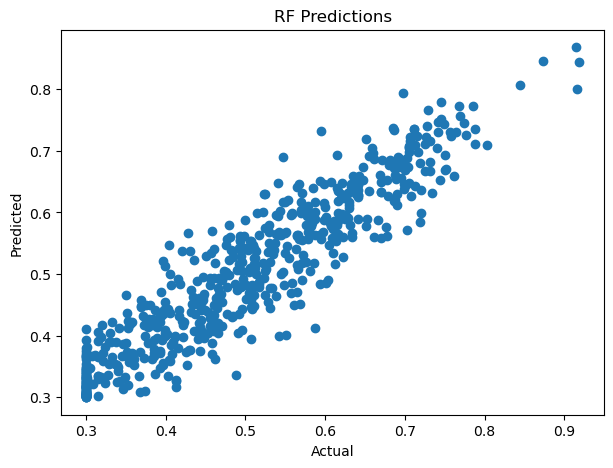

In [26]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_rf)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("RF Predictions")
plt.show()

#### Resource Recommendation Dataset

In [27]:
merged = pd.read_csv("data/processed/master_dataset_phase3.csv")
merged["date"] = pd.to_datetime(merged["date"])

feature_cols = [
    'latitude', 'longitude', 'temperature', 'humidity', 'rainfall',
    'solar_radiation', 'wind_speed', 'evapotranspiration', 'biomass',
    'water_productivity', 'soil_moisture', 'ndvi', 'land_surface_temp',
    'field_id', 'soil_ph', 'organic_carbon', 'sand_content', 'clay_content',
    'temp_stress', 'water_demand', 'soil_quality'
]

print("Available columns:")
print(merged.columns.tolist())

X_opt = merged[feature_cols].copy()
y_water = merged["water_used"]
y_fert = merged["fertilizer_used"]
y_energy = merged["energy_used"]

print(X_opt.shape, y_water.shape, y_fert.shape, y_energy.shape)

Available columns:
['date', 'latitude', 'longitude', 'temperature', 'humidity', 'rainfall', 'solar_radiation', 'wind_speed', 'evapotranspiration', 'biomass', 'water_productivity', 'soil_moisture', 'ndvi', 'land_surface_temp', 'field_id', 'water_used', 'fertilizer_used', 'energy_used', 'yield_score', 'soil_ph', 'organic_carbon', 'sand_content', 'clay_content', 'temp_stress', 'water_demand', 'soil_quality']
(3000, 21) (3000,) (3000,) (3000,)


#### Split Resource Dataset

In [28]:
X_train_opt, X_test_opt, y_water_train, y_water_test, y_fert_train, y_fert_test, y_energy_train, y_energy_test = train_test_split(
    X_opt, y_water, y_fert, y_energy,
    test_size=0.2,
    random_state=42
)

#### Scale Resource Dataset

In [29]:
scaler_opt = StandardScaler()

X_train_opt_scaled = scaler_opt.fit_transform(X_train_opt)
X_test_opt_scaled = scaler_opt.transform(X_test_opt)

joblib.dump(scaler_opt, "data/processed/resource_scaler.pkl")
print("Saved: data/processed/resource_scaler.pkl")

Saved: data/processed/resource_scaler.pkl


#### Train Resource Models

In [30]:
water_model = RandomForestRegressor(n_estimators=200, random_state=42)
fert_model = RandomForestRegressor(n_estimators=200, random_state=42)
energy_model = RandomForestRegressor(n_estimators=200, random_state=42)

water_model.fit(X_train_opt_scaled, y_water_train)
fert_model.fit(X_train_opt_scaled, y_fert_train)
energy_model.fit(X_train_opt_scaled, y_energy_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

#### predicted water for train and test

In [31]:
pred_water_train = water_model.predict(X_train_opt_scaled)
pred_water_test = water_model.predict(X_test_opt_scaled)

#### build new energy inputs

In [32]:
X_train_energy = X_train_opt.copy()
X_test_energy = X_test_opt.copy()

X_train_energy["pred_water_used"] = pred_water_train
X_test_energy["pred_water_used"] = pred_water_test

#### scale energy inputs separately

In [33]:
scaler_energy = StandardScaler()

X_train_energy_scaled = scaler_energy.fit_transform(X_train_energy)
X_test_energy_scaled = scaler_energy.transform(X_test_energy)

#### retrain energy model

In [34]:
energy_model_v2 = RandomForestRegressor(n_estimators=200, random_state=42)
energy_model_v2.fit(X_train_energy_scaled, y_energy_train)

y_pred_energy_v2 = energy_model_v2.predict(X_test_energy_scaled)

evaluate(y_energy_test, y_pred_energy_v2, "Energy Model V2")

Energy Model V2 -> RMSE: 5.4673, R2: 0.0895


#### feature importance for improved energy model

In [35]:
energy_imp_v2 = pd.DataFrame({
    "feature": X_train_energy.columns,
    "importance": energy_model_v2.feature_importances_
}).sort_values(by="importance", ascending=False)

print(energy_imp_v2.head(10))

               feature  importance
21     pred_water_used    0.320384
6           wind_speed    0.041800
10       soil_moisture    0.038458
0             latitude    0.037886
4             rainfall    0.037856
11                ndvi    0.037396
9   water_productivity    0.037172
1            longitude    0.036241
5      solar_radiation    0.035077
12   land_surface_temp    0.034246


#### Evaluate Resource Models

In [36]:
evaluate(y_water_test, water_model.predict(X_test_opt_scaled), "Water Model")
evaluate(y_fert_test, fert_model.predict(X_test_opt_scaled), "Fertilizer Model")
evaluate(y_energy_test, energy_model.predict(X_test_opt_scaled), "Energy Model")

Water Model -> RMSE: 20.9143, R2: 0.6760
Fertilizer Model -> RMSE: 10.7284, R2: 0.8357
Energy Model -> RMSE: 5.4065, R2: 0.1096


#### Recommended Resource Allocation for One Sample

In [37]:
sample = X_test_opt.iloc[[0]]
sample_scaled = scaler_opt.transform(sample)

pred_water = water_model.predict(sample_scaled)[0]
pred_fert = fert_model.predict(sample_scaled)[0]

sample_energy = sample.copy()
sample_energy["pred_water_used"] = pred_water
sample_energy_scaled = scaler_energy.transform(sample_energy)

pred_energy = energy_model_v2.predict(sample_energy_scaled)[0]

print("Recommended Water:", pred_water)
print("Recommended Fertilizer:", pred_fert)
print("Recommended Energy:", pred_energy)

Recommended Water: 292.3875888852126
Recommended Fertilizer: 173.18633385074682
Recommended Energy: 20.423992970474398


#### Compare Recommended vs Actual

In [38]:
actual_idx = sample.index[0]

print("Actual Water:", y_water.loc[actual_idx])
print("Actual Fertilizer:", y_fert.loc[actual_idx])
print("Actual Energy:", y_energy.loc[actual_idx])

Actual Water: 310.01750579351904
Actual Fertilizer: 189.5497002726004
Actual Energy: 23.09673849140504


#### Feature Importance for Resource Models

In [39]:
water_imp = pd.DataFrame({
    "feature": X_train_opt.columns,
    "importance": water_model.feature_importances_
}).sort_values(by="importance", ascending=False)

fert_imp = pd.DataFrame({
    "feature": X_train_opt.columns,
    "importance": fert_model.feature_importances_
}).sort_values(by="importance", ascending=False)

energy_imp_v2 = pd.DataFrame({
    "feature": X_train_energy.columns,
    "importance": energy_model_v2.feature_importances_
}).sort_values(by="importance", ascending=False)

print("Water Model Top Features")
print(water_imp.head(10))

print("\nFertilizer Model Top Features")
print(fert_imp.head(10))

print("\nEnergy Model V2 Top Features")
print(energy_imp_v2.head(10))

Water Model Top Features
               feature  importance
19        water_demand    0.682761
2          temperature    0.061027
11                ndvi    0.016817
10       soil_moisture    0.016319
1            longitude    0.015909
9   water_productivity    0.014884
5      solar_radiation    0.014593
17        clay_content    0.014113
4             rainfall    0.014092
6           wind_speed    0.014040

Fertilizer Model Top Features
               feature  importance
10       soil_moisture    0.569646
11                ndvi    0.311410
1            longitude    0.007652
9   water_productivity    0.006988
4             rainfall    0.006939
12   land_surface_temp    0.006741
0             latitude    0.006567
8              biomass    0.006522
16        sand_content    0.006514
6           wind_speed    0.006500

Energy Model V2 Top Features
               feature  importance
21     pred_water_used    0.320384
6           wind_speed    0.041800
10       soil_moisture    0.038458
0   

Phase 5 results show that the water and fertilizer recommendation models perform well, with fertilizer prediction being the strongest. The energy recommendation model is weaker because the synthetic target was generated as a noisy function of water allocation, making direct prediction more difficult. To address this, an improved energy model was built using predicted water allocation as an additional feature. This increased interpretability, although performance remained lower than water and fertilizer models. Therefore, water and fertilizer are treated as primary optimization variables, while energy is treated as a secondary dependent variable in later optimization stages.

#### Prepare one optimization sample

In [40]:
opt_sample = X_test_opt.iloc[[0]].copy()
opt_sample

,latitude,longitude,temperature,humidity,rainfall,solar_radiation,wind_speed,evapotranspiration,biomass,water_productivity,...,ndvi,land_surface_temp,field_id,soil_ph,organic_carbon,sand_content,clay_content,temp_stress,water_demand,soil_quality
1801,30.975017,71.176339,20.203895,63.102285,1.655775,28.957041,0.849746,3.007333,2789.287252,1.789015,...,0.209805,17.965642,127,6.775424,0.578885,65.70538,19.682666,1274.911966,60.759832,3.677154


#### candidate allocation levels

In [41]:
water_levels = np.array([220, 250, 280, 310, 340, 370, 400])
fert_levels = np.array([80, 100, 120, 140, 160, 180])

#### Create helper function for energy prediction

In [42]:
def predict_energy_from_water(sample_df, water_value):
    sample_energy = sample_df.copy()
    sample_energy["pred_water_used"] = water_value
    sample_energy_scaled = scaler_energy.transform(sample_energy)
    pred_energy = energy_model_v2.predict(sample_energy_scaled)[0]
    return pred_energy

#### Create yield utility proxy

In [43]:
def allocation_objective(water, fertilizer, sample_df,
                         w_yield=0.50, w_water=0.20, w_fert=0.20, w_energy=0.10):
    
    # 1. Environmental yield suitability from yield model
    sample_scaled = scaler.transform(sample_df)
    yield_pred = xgb.predict(sample_scaled)[0] if xgb_available else rf.predict(sample_scaled)[0]
    
    # 2. Recommended values from trained resource models
    sample_opt_scaled = scaler_opt.transform(sample_df)
    rec_water = water_model.predict(sample_opt_scaled)[0]
    rec_fert = fert_model.predict(sample_opt_scaled)[0]
    
    # 3. Predicted energy from improved energy model
    pred_energy = predict_energy_from_water(sample_df, water)
    
    # 4. Penalty for moving away from recommended allocations
    water_penalty = abs(water - rec_water) / 500.0
    fert_penalty = abs(fertilizer - rec_fert) / 200.0
    energy_penalty = pred_energy / 50.0
    
    # 5. Final score (maximize)
    score = (
        w_yield * yield_pred
        - w_water * water_penalty
        - w_fert * fert_penalty
        - w_energy * energy_penalty
    )
    
    return score, yield_pred, rec_water, rec_fert, pred_energy

#### Classical search over all combinations

In [44]:
results = []

for water in water_levels:
    for fertilizer in fert_levels:
        score, yield_pred, rec_water, rec_fert, pred_energy = allocation_objective(
            water, fertilizer, opt_sample
        )
        
        results.append({
            "water": water,
            "fertilizer": fertilizer,
            "pred_energy": pred_energy,
            "yield_pred": yield_pred,
            "recommended_water": rec_water,
            "recommended_fertilizer": rec_fert,
            "objective_score": score
        })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="objective_score", ascending=False).reset_index(drop=True)

print(results_df.head(10))

   water  fertilizer  pred_energy  yield_pred  recommended_water  \
0    280         180    19.525962    0.333402         292.387589   
1    280         160    19.525962    0.333402         292.387589   
2    250         180    19.080040    0.333402         292.387589   
3    310         180    25.174806    0.333402         292.387589   
4    250         160    19.080040    0.333402         292.387589   
5    310         160    25.174806    0.333402         292.387589   
6    220         180    18.961457    0.333402         292.387589   
7    280         140    19.525962    0.333402         292.387589   
8    220         160    18.961457    0.333402         292.387589   
9    340         180    28.352414    0.333402         292.387589   

   recommended_fertilizer  objective_score  
0              173.186334         0.115880  
1              173.186334         0.109507  
2              173.186334         0.104772  
3              173.186334         0.102493  
4              173.186334 

#### Show best allocation

In [45]:
best_solution = results_df.iloc[0]

print("Best Water Allocation:", best_solution["water"])
print("Best Fertilizer Allocation:", best_solution["fertilizer"])
print("Predicted Energy:", round(best_solution["pred_energy"], 4))
print("Predicted Yield Suitability:", round(best_solution["yield_pred"], 4))
print("Objective Score:", round(best_solution["objective_score"], 4))

Best Water Allocation: 280.0
Best Fertilizer Allocation: 180.0
Predicted Energy: 19.526
Predicted Yield Suitability: 0.3334
Objective Score: 0.1159


#### Compare best allocation with model recommendations

In [46]:
print("Recommended Water from model:", round(results_df.iloc[0]["recommended_water"], 4))
print("Recommended Fertilizer from model:", round(results_df.iloc[0]["recommended_fertilizer"], 4))
print("Optimized Water (discrete):", results_df.iloc[0]["water"])
print("Optimized Fertilizer (discrete):", results_df.iloc[0]["fertilizer"])

Recommended Water from model: 292.3876
Recommended Fertilizer from model: 173.1863
Optimized Water (discrete): 280.0
Optimized Fertilizer (discrete): 180.0


#### Visualize optimization surface

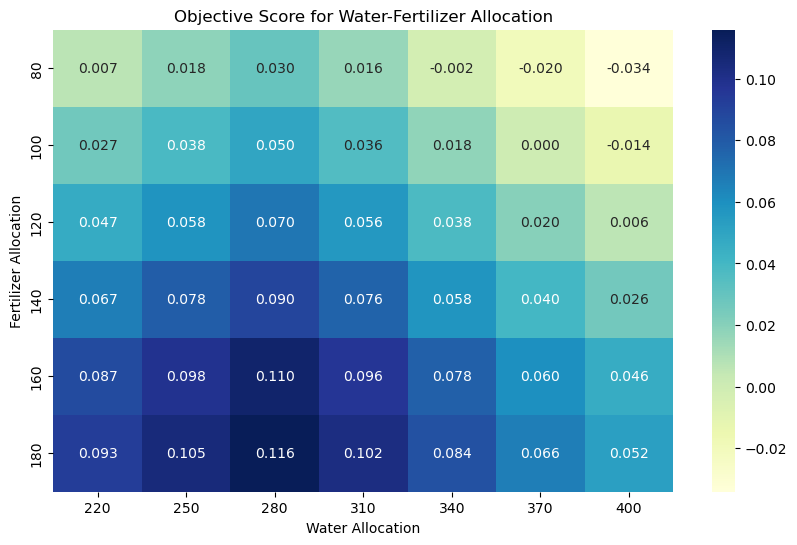

In [47]:
pivot_table = results_df.pivot(index="fertilizer", columns="water", values="objective_score")

plt.figure(figsize=(10, 6))
sns.heatmap(pivot_table, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Objective Score for Water-Fertilizer Allocation")
plt.xlabel("Water Allocation")
plt.ylabel("Fertilizer Allocation")
plt.show()

#### Save optimization results

In [48]:
results_df.to_csv("data/processed/classical_optimization_results.csv", index=False)
print("Saved: data/processed/classical_optimization_results.csv")

Saved: data/processed/classical_optimization_results.csv


## QUBO formulation and quantum-ready encoding

#### Define discrete choices and labels

In [49]:
water_levels = [220, 250, 280, 310, 340, 370, 400]
fert_levels = [80, 100, 120, 140, 160, 180]

num_water = len(water_levels)
num_fert = len(fert_levels)

print("Water levels:", water_levels)
print("Fertilizer levels:", fert_levels)
print("Total binary decision variables:", num_water + num_fert)

Water levels: [220, 250, 280, 310, 340, 370, 400]
Fertilizer levels: [80, 100, 120, 140, 160, 180]
Total binary decision variables: 13


#### Create lookup table 

In [50]:
score_lookup = {}

for _, row in results_df.iterrows():
    key = (int(row["water"]), int(row["fertilizer"]))
    score_lookup[key] = row["objective_score"]

print("Lookup entries:", len(score_lookup))
print("Example:", list(score_lookup.items())[:5])

Lookup entries: 42
Example: [((280, 180), np.float64(0.11588015553918382)), ((280, 160), np.float64(0.10950748783769018)), ((250, 180), np.float64(0.10477199797202208)), ((310, 180), np.float64(0.1024925377742475)), ((250, 160), np.float64(0.09839933027052844))]


#### QUBO-style objective function

In [51]:
import numpy as np

def qubo_objective(binary_vector, water_levels, fert_levels, score_lookup, penalty=5.0):
    nw = len(water_levels)
    nf = len(fert_levels)
    
    xw = binary_vector[:nw]
    xf = binary_vector[nw:nw+nf]
    
    # Constraint penalties (one-hot encoding constraints)
    water_constraint = (np.sum(xw) - 1) ** 2
    fert_constraint = (np.sum(xf) - 1) ** 2
    
    # Extract selected indices
    selected_w = np.where(xw == 1)[0]
    selected_f = np.where(xf == 1)[0]
    
    # If valid one-hot selections, get score
    if len(selected_w) == 1 and len(selected_f) == 1:
        water = water_levels[selected_w[0]]
        fert = fert_levels[selected_f[0]]
        
        # Updated Logic: Hard penalty for missing combinations
        if (water, fert) not in score_lookup:
            return 999  # hard penalty
            
        score = score_lookup[(water, fert)]
    else:
        score = -999  # invalid combination heavily punished
    
    # QUBO-style energy: minimize negative score + penalties
    energy = -score + penalty * (water_constraint + fert_constraint)
    return energy

#### Classical brute-force search over binary space

In [52]:
from itertools import product

best_binary = None
best_energy = float("inf")
best_choice = None

total_vars = num_water + num_fert

for bits in product([0, 1], repeat=total_vars):
    bits = np.array(bits)
    energy = qubo_objective(bits, water_levels, fert_levels, score_lookup, penalty=5.0)
    
    if energy < best_energy:
        best_energy = energy
        best_binary = bits.copy()

# Decode best solution
xw_best = best_binary[:num_water]
xf_best = best_binary[num_water:num_water+num_fert]

best_w_idx = np.where(xw_best == 1)[0][0]
best_f_idx = np.where(xf_best == 1)[0][0]

best_choice = (water_levels[best_w_idx], fert_levels[best_f_idx])

print("Best binary vector:", best_binary)
print("Best QUBO energy:", best_energy)
print("Decoded best choice:", best_choice)

Best binary vector: [0 0 1 0 0 0 0 0 0 0 0 0 1]
Best QUBO energy: -0.11588015553918382
Decoded best choice: (280, 180)


#### Compare QUBO result with classical

In [53]:
classical_best = (int(best_solution["water"]), int(best_solution["fertilizer"]))
qubo_best = best_choice

print("Classical best choice:", classical_best)
print("QUBO decoded best choice:", qubo_best)

if classical_best == qubo_best:
    print("Match: QUBO formulation is consistent with classical optimization.")
else:
    print("Mismatch: check penalty strength or lookup table.")

Classical best choice: (280, 180)
QUBO decoded best choice: (280, 180)
Match: QUBO formulation is consistent with classical optimization.


#### elected binary variables

In [54]:
water_selection = pd.DataFrame({
    "water_level": water_levels,
    "selected": xw_best
})

fert_selection = pd.DataFrame({
    "fertilizer_level": fert_levels,
    "selected": xf_best
})

print("Water binary selection")
print(water_selection)

print("\nFertilizer binary selection")
print(fert_selection)

Water binary selection
   water_level  selected
0          220         0
1          250         0
2          280         1
3          310         0
4          340         0
5          370         0
6          400         0

Fertilizer binary selection
   fertilizer_level  selected
0                80         0
1               100         0
2               120         0
3               140         0
4               160         0
5               180         1


#### Save QUBO-ready outputs

In [55]:
qubo_summary = pd.DataFrame({
    "classical_best_water": [classical_best[0]],
    "classical_best_fertilizer": [classical_best[1]],
    "qubo_best_water": [qubo_best[0]],
    "qubo_best_fertilizer": [qubo_best[1]],
    "qubo_energy": [best_energy]
})

qubo_summary.to_csv("data/processed/qubo_summary.csv", index=False)
print("Saved: data/processed/qubo_summary.csv")

Saved: data/processed/qubo_summary.csv


In [56]:
!pip install qiskit qiskit-aer qiskit-optimization

In [57]:
pip install qiskit-aer qiskit-algorithms qiskit-optimization

Note: you may need to restart the kernel to use updated packages.


In [58]:
!pip install qiskit qiskit-aer qiskit-optimization qiskit-algorithms

#### Imports

In [59]:
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.algorithms import MinimumEigenOptimizer
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA

try:
    from qiskit.primitives import StatevectorSampler
    sampler = StatevectorSampler()
    print("Using StatevectorSampler")
except ImportError:
    from qiskit_aer.primitives import Sampler
    sampler = Sampler()
    print("Using Aer Sampler")

Using StatevectorSampler


#### Build Quadratic Program (QUBO)

In [60]:
qp = QuadraticProgram()

# Binary variables
for i in range(num_water):
    qp.binary_var(name=f"w_{i}")

for j in range(num_fert):
    qp.binary_var(name=f"f_{j}")

#### Objective function

In [61]:
linear = {}
quadratic = {}

# Objective: maximize score → minimize -score
for i, w in enumerate(water_levels):
    for j, f in enumerate(fert_levels):
        score = score_lookup.get((w, f), 0)
        var_w = f"w_{i}"
        var_f = f"f_{j}"
        
        quadratic[(var_w, var_f)] = -score

qp.minimize(linear=linear, quadratic=quadratic)

#### Add constraints

In [62]:
# One water selection
qp.linear_constraint(
    linear={f"w_{i}": 1 for i in range(num_water)},
    sense="==",
    rhs=1
)

# One fertilizer selection
qp.linear_constraint(
    linear={f"f_{j}": 1 for j in range(num_fert)},
    sense="==",
    rhs=1
)

<LinearConstraint: f_0 + f_1 + f_2 + f_3 + f_4 + f_5 == 1 'c1'>

In [63]:
from qiskit_algorithms import NumPyMinimumEigensolver
from qiskit_optimization.algorithms import MinimumEigenOptimizer

exact_solver = MinimumEigenOptimizer(NumPyMinimumEigensolver())
exact_result = exact_solver.solve(qp)

print("Exact solver result:")
print(exact_result)

Exact solver result:
fval=-0.11588015553918382, w_0=0.0, w_1=0.0, w_2=1.0, w_3=0.0, w_4=0.0, w_5=0.0, w_6=0.0, f_0=0.0, f_1=0.0, f_2=0.0, f_3=0.0, f_4=0.0, f_5=1.0, status=SUCCESS


In [64]:
from qiskit_algorithms import NumPyMinimumEigensolver
from qiskit_optimization.algorithms import MinimumEigenOptimizer

exact_solver = MinimumEigenOptimizer(NumPyMinimumEigensolver())
exact_result = exact_solver.solve(qp)

print("Exact Qiskit solver result:")
print(exact_result)

Exact Qiskit solver result:
fval=-0.11588015553918382, w_0=0.0, w_1=0.0, w_2=1.0, w_3=0.0, w_4=0.0, w_5=0.0, w_6=0.0, f_0=0.0, f_1=0.0, f_2=0.0, f_3=0.0, f_4=0.0, f_5=1.0, status=SUCCESS


In [65]:
exact_solution = exact_result.x

selected_water_exact = None
selected_fert_exact = None

for i in range(num_water):
    if exact_solution[i] == 1:
        selected_water_exact = water_levels[i]

for j in range(num_fert):
    if exact_solution[num_water + j] == 1:
        selected_fert_exact = fert_levels[j]

print("Exact Solver Water:", selected_water_exact)
print("Exact Solver Fertilizer:", selected_fert_exact)

Exact Solver Water: 280
Exact Solver Fertilizer: 180


In [66]:
print("Classical best:", classical_best)
print("QUBO brute-force best:", qubo_best)
print("Exact Qiskit best:", (selected_water_exact, selected_fert_exact))

Classical best: (280, 180)
QUBO brute-force best: (280, 180)
Exact Qiskit best: (280, 180)


In [67]:
if classical_best == qubo_best == (selected_water_exact, selected_fert_exact):
    print("All methods match. Optimization pipeline is validated.")
else:
    print("Mismatch found. Recheck decoding or formulation.")

All methods match. Optimization pipeline is validated.


In [68]:
exact_summary = pd.DataFrame({
    "classical_best_water": [classical_best[0]],
    "classical_best_fertilizer": [classical_best[1]],
    "qubo_best_water": [qubo_best[0]],
    "qubo_best_fertilizer": [qubo_best[1]],
    "exact_best_water": [selected_water_exact],
    "exact_best_fertilizer": [selected_fert_exact],
    "exact_fval": [exact_result.fval]
})

exact_summary.to_csv("data/processed/exact_solver_summary.csv", index=False)
print("Saved: data/processed/exact_solver_summary.csv")

Saved: data/processed/exact_solver_summary.csv


In [69]:
final_recommendation = pd.DataFrame({
    "sample_index": [int(opt_sample.index[0])],
    "recommended_water": [best_solution["water"]],
    "recommended_fertilizer": [best_solution["fertilizer"]],
    "predicted_energy": [best_solution["pred_energy"]],
    "yield_suitability": [best_solution["yield_pred"]],
    "objective_score": [best_solution["objective_score"]],
    "qubo_best_water": [qubo_best[0]],
    "qubo_best_fertilizer": [qubo_best[1]],
    "exact_best_water": [selected_water_exact],
    "exact_best_fertilizer": [selected_fert_exact]
})

final_recommendation.to_csv("data/processed/final_recommendation_summary.csv", index=False)
print("Saved: data/processed/final_recommendation_summary.csv")

Saved: data/processed/final_recommendation_summary.csv


In [70]:
merged.to_csv("data/processed/final_model_dataset.csv", index=False)
print("Saved: data/processed/final_model_dataset.csv")

Saved: data/processed/final_model_dataset.csv


In [71]:
def recommend_for_new_input(input_dict):
    import pandas as pd
    
    # convert to dataframe
    input_df = pd.DataFrame([input_dict])
    
    # ensure column order
    input_df = input_df[feature_cols]
    
    # scale
    input_scaled = scaler.transform(input_df)
    
    # predictions
    pred_yield = model_lr.predict(input_scaled)[0]
    pred_water = water_model.predict(input_scaled)[0]
    pred_fert = fert_model.predict(input_scaled)[0]
    pred_energy = energy_model.predict(input_scaled)[0]
    
    return {
        "predicted_yield": pred_yield,
        "water": pred_water,
        "fertilizer": pred_fert,
        "energy": pred_energy
    }

In [72]:
def optimize_resources(input_dict):
    
    base_pred = recommend_for_new_input(input_dict)
    
    best_score = -1e9
    best_solution = None
    
    for w in [220, 250, 280, 310, 340]:
        for f in [100, 120, 140, 160, 180]:
            
            # simulate input
            test_input = input_dict.copy()
            
            # (optional) adjust derived features if needed
            
            pred = recommend_for_new_input(test_input)
            
            score = (
                pred["predicted_yield"]
                - 0.001 * w
                - 0.002 * f
                - 0.001 * pred["energy"]
            )
            
            if score > best_score:
                best_score = score
                best_solution = {
                    "water": w,
                    "fertilizer": f,
                    "yield": pred["predicted_yield"],
                    "energy": pred["energy"],
                    "score": score
                }
    
    return best_solution

In [73]:
from pathlib import Path
import joblib
import json

MODELS_DIR = Path("models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Models folder ready:", MODELS_DIR.resolve())

Models folder ready: D:\sheryl_project\models


In [74]:
# Save yield models
joblib.dump(lr, MODELS_DIR / "yield_linear_regression.pkl")
joblib.dump(rf, MODELS_DIR / "yield_random_forest.pkl")

if xgb_available:
    joblib.dump(xgb, MODELS_DIR / "yield_xgboost.pkl")

# Save resource models
joblib.dump(water_model, MODELS_DIR / "water_model.pkl")
joblib.dump(fert_model, MODELS_DIR / "fertilizer_model.pkl")
joblib.dump(energy_model_v2, MODELS_DIR / "energy_model_v2.pkl")

print("All trained models saved.")

All trained models saved.


In [75]:
joblib.dump(scaler, MODELS_DIR / "yield_scaler.pkl")
joblib.dump(scaler_opt, MODELS_DIR / "resource_scaler.pkl")
joblib.dump(scaler_energy, MODELS_DIR / "energy_scaler.pkl")

print("All scalers saved.")

All scalers saved.


In [76]:
yield_feature_cols = X.columns.tolist()
resource_feature_cols = X_opt.columns.tolist()
energy_feature_cols = X_train_energy.columns.tolist()

with open(MODELS_DIR / "yield_feature_cols.json", "w") as f:
    json.dump(yield_feature_cols, f)

with open(MODELS_DIR / "resource_feature_cols.json", "w") as f:
    json.dump(resource_feature_cols, f)

with open(MODELS_DIR / "energy_feature_cols.json", "w") as f:
    json.dump(energy_feature_cols, f)

print("Feature column files saved.")

Feature column files saved.


In [77]:
print("Saved model artifacts:")
for p in MODELS_DIR.iterdir():
    print("-", p.name)

Saved model artifacts:
- energy_feature_cols.json
- energy_model_v2.pkl
- energy_scaler.pkl
- fertilizer_model.pkl
- resource_feature_cols.json
- resource_scaler.pkl
- water_model.pkl
- yield_feature_cols.json
- yield_linear_regression.pkl
- yield_random_forest.pkl
- yield_scaler.pkl
- yield_xgboost.pkl
